File: chapter_06_A.ipynb<br>
Desc: Ensemble Techniques

---

In [70]:
import sys
print(sys.version)
print(sys.executable)


3.13.1 (v3.13.1:06714517797, Dec  3 2024, 14:00:22) [Clang 15.0.0 (clang-1500.3.9.4)]
/usr/local/bin/python3


In [71]:
import sys
!{sys.executable} -m pip install --upgrade --force-reinstall xgboost


  Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl.metadata (2.0 kB)
  Using cached numpy-2.5.3-cp313-cp313-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached scipy-1.18.1-cp313-cp313-macosx_14_0_arm64.whl.metadata (62 kB)
Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl (2.4 MB)
Using cached numpy-2.5.3-cp313-cp313-macosx_14_0_arm64.whl (5.4 MB)
Using cached scipy-1.18.1-cp313-cp313-macosx_14_0_arm64.whl (20.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.3
    Uninstalling numpy-2.5.3:
      Successfully uninstalled numpy-2.5.3
  Attempting uninstall: scipy━━━━━━━━━━━━━━━━━━━ 0/3 [numpy]
    Found existing installation: scipy 1.18.1 0/3 [numpy]
    Uninstalling scipy-1.18.1:╺━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/3 [scipy]
      Successfully uninstalled scipy-1.18.1━━━━━━━━━━━━━━━━━━━ 1/3 [scipy]
  Attempting uninstall: xgboost━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/3 [scipy]
    Found existing installation: xgboost 3.4.10m━━━━━━━━━━━━━ 2/3 [xgboost]
 

Section 01 : Data Inspection

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [73]:
df_temp = pd.read_csv("dataset.csv")
print("Number of Rows = ", df_temp.shape[0])
print("Number of Cols = ", df_temp.shape[1])

Number of Rows =  42767
Number of Cols =  12


In [74]:
num_of_class_1 = df_temp['LABEL'].value_counts()[0]
num_of_class_2 = df_temp['LABEL'].value_counts()[1]
print("Number of Class 0 = ", num_of_class_1)
print("Number of Class 1 = ", num_of_class_2)
print("Imbalance Ratio = 1 :", num_of_class_1 / num_of_class_2)

Number of Class 0 =  35132
Number of Class 1 =  7635
Imbalance Ratio = 1 : 4.601440733464309


1. Inspect "SEX"

In [75]:
df_temp['SEX'].value_counts()

SEX
1    38527
0     4240
Name: count, dtype: int64

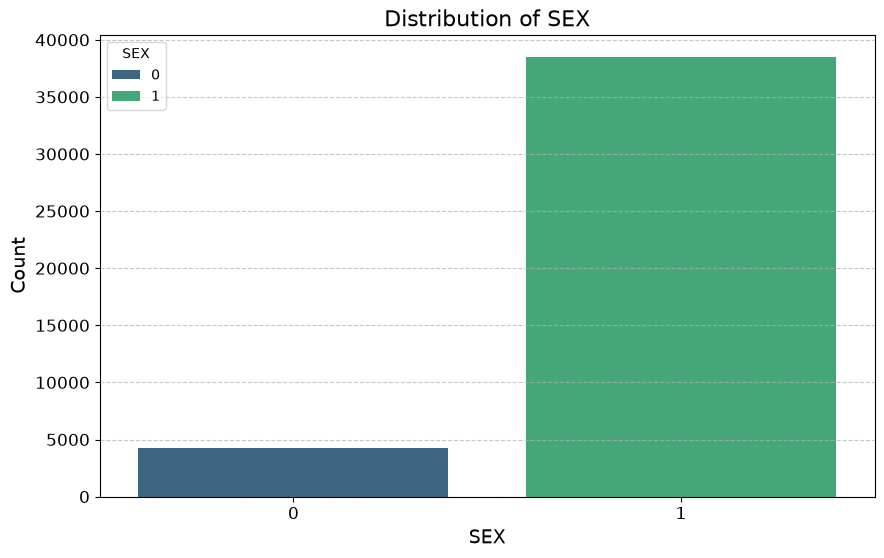

In [76]:
sex_counts = df_temp['SEX'].value_counts().reset_index()
sex_counts.columns = ['SEX', 'Count']

plt.figure(figsize=(10, 6))
sns.barplot(data=sex_counts, x='SEX', y='Count', hue='SEX', palette='viridis', dodge=False)
plt.title('Distribution of SEX', fontsize=16)
plt.xlabel('SEX', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7);

2. Inspect "NUMBER_OF_DEPENDENT"

In [77]:
print(df_temp['NO_OF_DEPENDENT'].describe())
print("skewness = ", df_temp['NO_OF_DEPENDENT'].skew())
print("kurtosis = ", df_temp['NO_OF_DEPENDENT'].kurt())

count    42767.000000
mean         0.936774
std          1.286007
min          0.000000
25%          0.000000
50%          0.000000
75%          2.000000
max         34.000000
Name: NO_OF_DEPENDENT, dtype: float64
skewness =  1.8269598522790584
kurtosis =  14.916908140061953


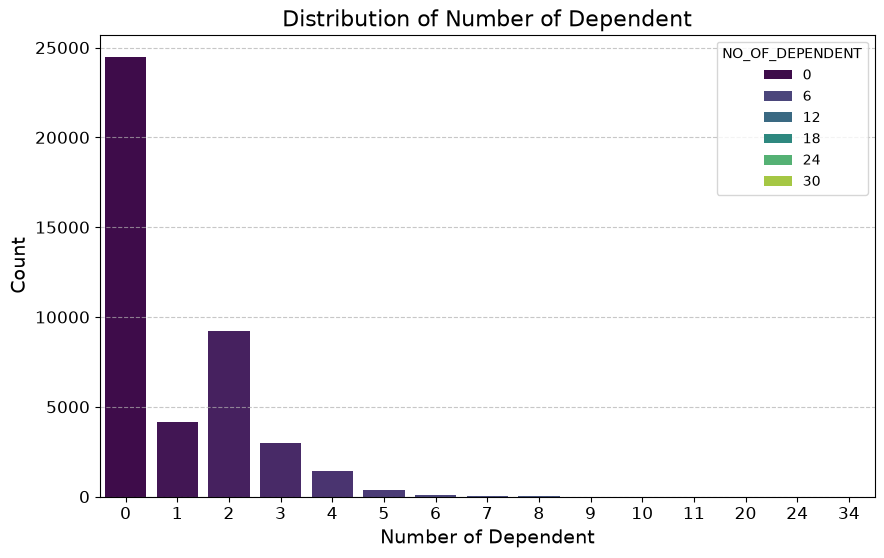

In [78]:
number_of_dependent_counts = df_temp['NO_OF_DEPENDENT'].value_counts().reset_index()
number_of_dependent_counts.columns = ['NO_OF_DEPENDENT', 'Count']

plt.figure(figsize=(10, 6))
sns.barplot(data=number_of_dependent_counts, x='NO_OF_DEPENDENT', y='Count', hue='NO_OF_DEPENDENT', palette='viridis', dodge=False)
plt.title('Distribution of Number of Dependent', fontsize=16)
plt.xlabel('Number of Dependent', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7);

3. Inspect "MARITAL_STATUS"

In [79]:
df_temp['MARITAL_STATUS'].value_counts()

MARITAL_STATUS
1    31365
2    11292
3       76
0       34
Name: count, dtype: int64

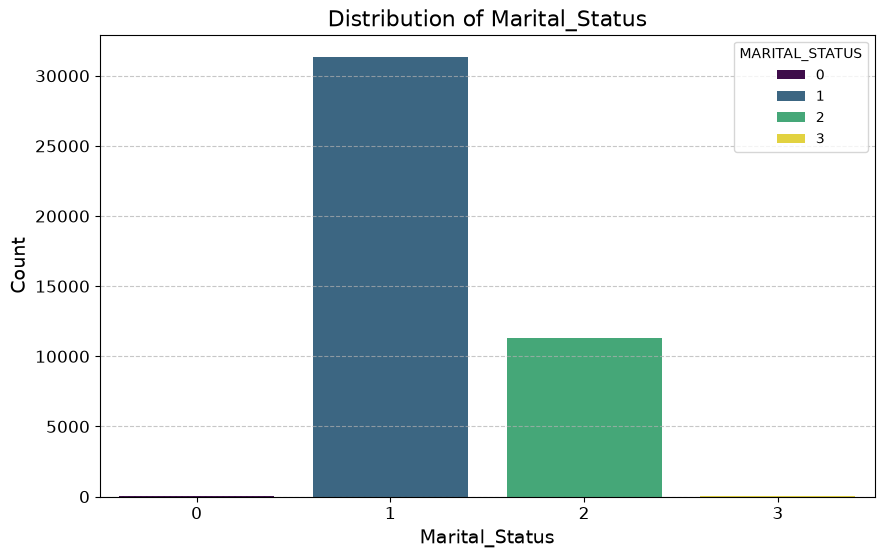

In [80]:
marital_status_counts = df_temp['MARITAL_STATUS'].value_counts().reset_index()
marital_status_counts.columns = ['MARITAL_STATUS', 'Count']

plt.figure(figsize=(10, 6))
sns.barplot(data=marital_status_counts, x='MARITAL_STATUS', y='Count', hue='MARITAL_STATUS', palette='viridis', dodge=False)
plt.title('Distribution of Marital_Status', fontsize=16)
plt.xlabel('Marital_Status', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7);

4. Inspect "YRS_IN_PRESENT_JOB"

In [81]:
print(df_temp['YRS_IN_PRESENT_JOB'].describe())
print("skewness = ", df_temp['YRS_IN_PRESENT_JOB'].skew())
print("kurtosis = ", df_temp['YRS_IN_PRESENT_JOB'].kurt())

count    42767.000000
mean         6.206982
std          6.155208
min          0.000000
25%          2.000000
50%          4.000000
75%          8.000000
max         60.000000
Name: YRS_IN_PRESENT_JOB, dtype: float64
skewness =  2.1156452469051352
kurtosis =  4.937914065015972


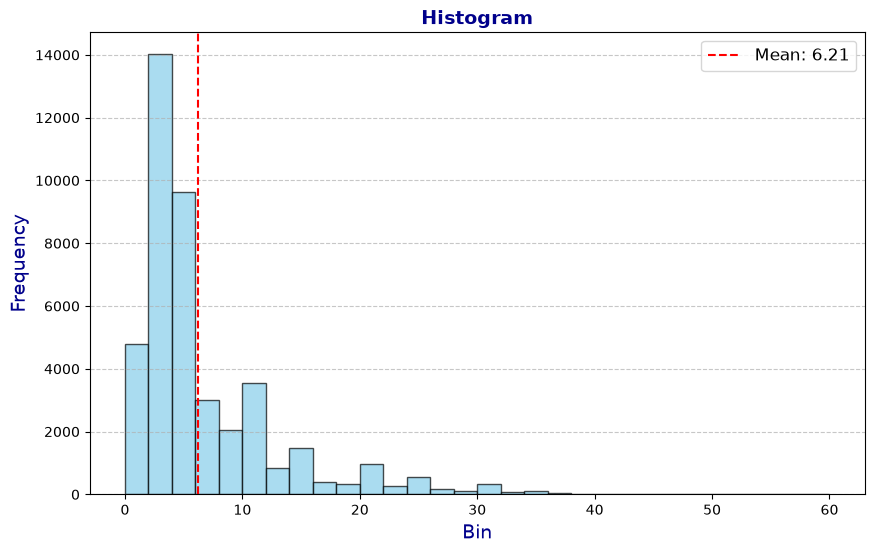

In [82]:
plt.figure(figsize=(10, 6))
plt.hist(df_temp['YRS_IN_PRESENT_JOB'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram', fontsize=14, fontweight='bold', color='darkblue')
plt.xlabel('Bin', fontsize=14, color='darkblue')
plt.ylabel('Frequency', fontsize=14, color='darkblue')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add annotations
mean_value = df_temp['YRS_IN_PRESENT_JOB'].mean()
plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1.5, label=f'Mean: {mean_value:.2f}')
plt.legend(fontsize=12);

5. Inspect feature 'AGE'

In [83]:
print(df_temp['AGE'].describe())
print("skewness = ", df_temp['AGE'].skew())
print("kurtosis = ", df_temp['AGE'].kurt())

count    42767.000000
mean        32.862581
std          9.578984
min         18.000000
25%         25.000000
50%         31.000000
75%         39.000000
max         71.000000
Name: AGE, dtype: float64
skewness =  0.7459740809271862
kurtosis =  -0.2510415794372234


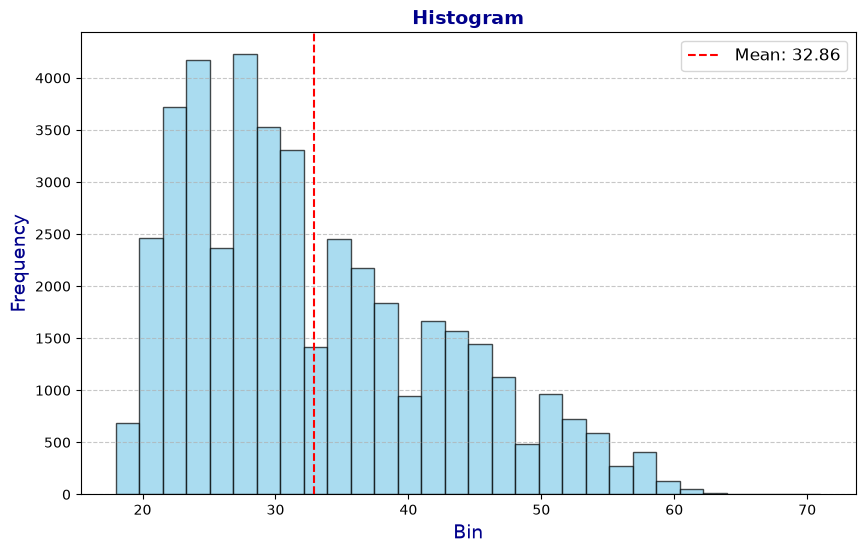

In [84]:
plt.figure(figsize=(10, 6))
plt.hist(df_temp['AGE'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram', fontsize=14, fontweight='bold', color='darkblue')
plt.xlabel('Bin', fontsize=14, color='darkblue')
plt.ylabel('Frequency', fontsize=14, color='darkblue')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add annotations
mean_value = df_temp['AGE'].mean()
plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1.5, label=f'Mean: {mean_value:.2f}')
plt.legend(fontsize=12);


6. Inspect feature "EDUCATION"

In [85]:
df_temp['EDUCATION'].value_counts()

EDUCATION
1    18787
0    15610
3     7400
2      970
Name: count, dtype: int64

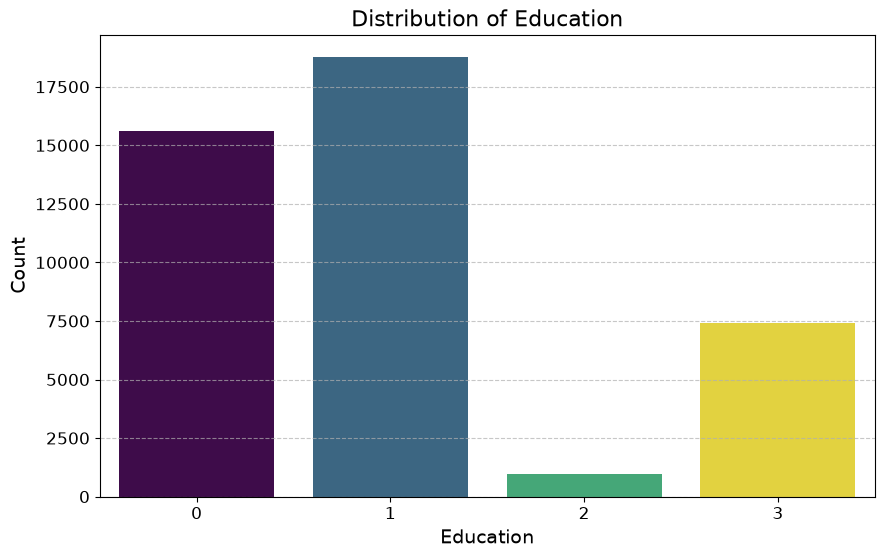

In [86]:
company_type_counts = df_temp['EDUCATION'].value_counts().reset_index()
company_type_counts.columns = ['EDUCATION', 'Count']

plt.figure(figsize=(10, 6))
sns.barplot(data=company_type_counts, x='EDUCATION', y='Count', hue='EDUCATION', palette='viridis', dodge=False)
plt.title('Distribution of Education', fontsize=16)
plt.xlabel('Education', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend([], [], frameon=False)  # ซ่อน legend
plt.grid(axis='y', linestyle='--', alpha=0.7);

7. Inspect "YEARS_OF_EXPERIENCE"

In [87]:
print(df_temp['YEARS_OF_EXPERIENCE'].describe())
print("skewness = ", df_temp['YEARS_OF_EXPERIENCE'].skew())
print("kurtosis = ", df_temp['YEARS_OF_EXPERIENCE'].kurt())

count    42767.000000
mean         6.448734
std          6.614030
min          0.000000
25%          2.000000
50%          4.000000
75%          8.000000
max         70.000000
Name: YEARS_OF_EXPERIENCE, dtype: float64
skewness =  2.1897416300864947
kurtosis =  6.081632278878567


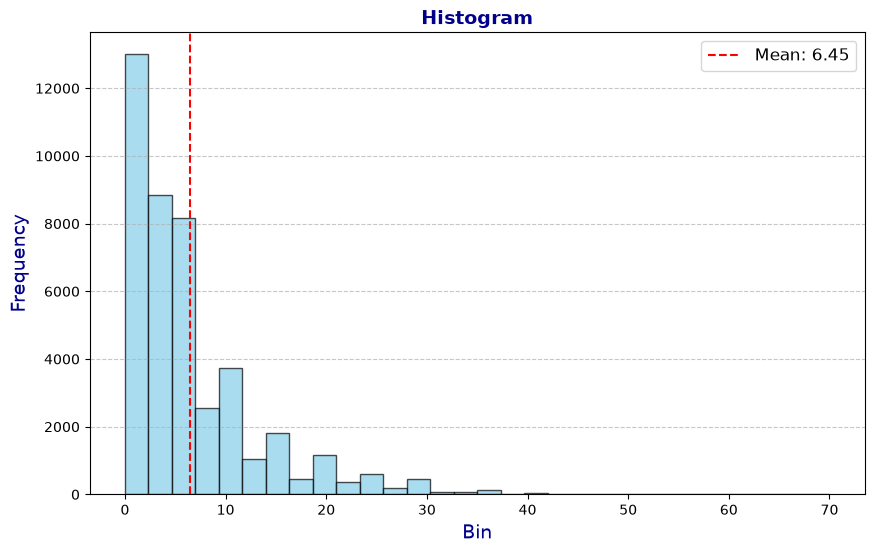

In [88]:
plt.figure(figsize=(10, 6))
plt.hist(df_temp['YEARS_OF_EXPERIENCE'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram', fontsize=14, fontweight='bold', color='darkblue')
plt.xlabel('Bin', fontsize=14, color='darkblue')
plt.ylabel('Frequency', fontsize=14, color='darkblue')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add annotations
mean_value = df_temp['YEARS_OF_EXPERIENCE'].mean()
plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1.5, label=f'Mean: {mean_value:.2f}')
plt.legend(fontsize=12);

8. Inspect "TOTAL_MONTHLY_INCOME"

In [89]:
print(df_temp['TOTAL_MONTHLY_INCOME'].describe())
print("skewness = ", df_temp['TOTAL_MONTHLY_INCOME'].skew())
print("kurtosis = ", df_temp['TOTAL_MONTHLY_INCOME'].kurt())

count     42767.000000
mean      16262.705402
std       11733.142841
min           0.000000
25%       10500.000000
50%       14000.000000
75%       18000.000000
max      750000.000000
Name: TOTAL_MONTHLY_INCOME, dtype: float64
skewness =  14.847986073726137
kurtosis =  571.5282805240147


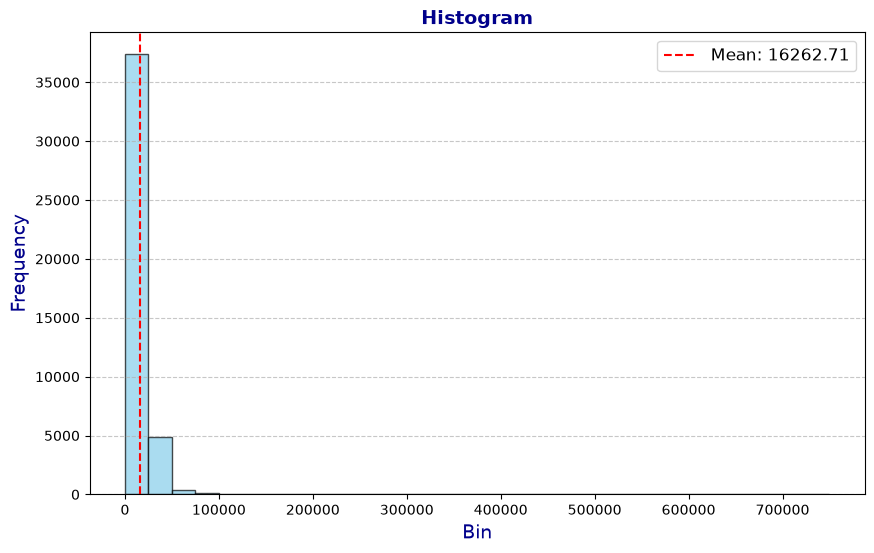

In [90]:
plt.figure(figsize=(10, 6))
plt.hist(df_temp['TOTAL_MONTHLY_INCOME'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram', fontsize=14, fontweight='bold', color='darkblue')
plt.xlabel('Bin', fontsize=14, color='darkblue')
plt.ylabel('Frequency', fontsize=14, color='darkblue')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add annotations
mean_value = df_temp['TOTAL_MONTHLY_INCOME'].mean()
plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1.5, label=f'Mean: {mean_value:.2f}')
plt.legend(fontsize=12);

9. Inspect feature "LOAN_AMOUNT"

In [91]:
print(df_temp['LOAN_AMOUNT'].describe())
print("skewness = ", df_temp['LOAN_AMOUNT'].skew())
print("kurtosis = ", df_temp['LOAN_AMOUNT'].kurt())

count    42767.000000
mean     51000.949213
std       6517.500079
min      22830.000000
25%      47578.000000
50%      51588.000000
75%      55064.000000
max      96747.000000
Name: LOAN_AMOUNT, dtype: float64
skewness =  -0.15493008002133463
kurtosis =  0.7267804472693751


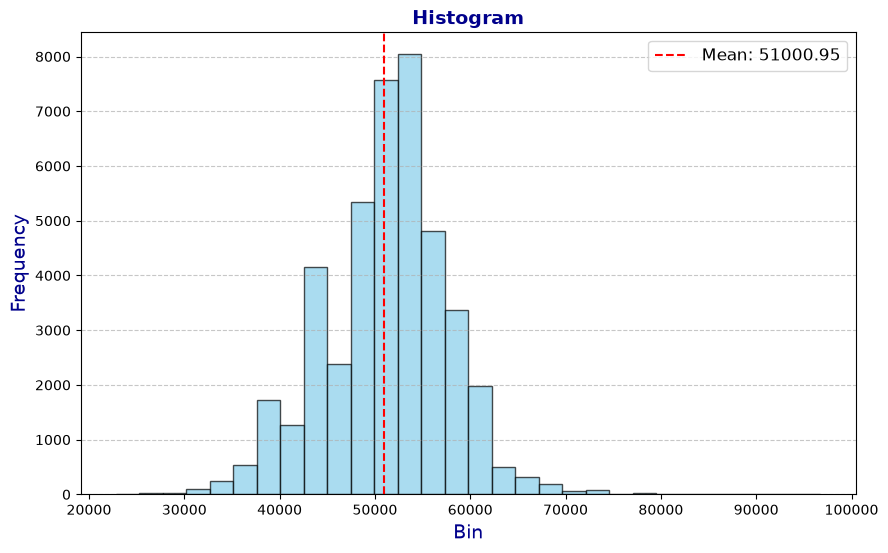

In [92]:
plt.figure(figsize=(10, 6))
plt.hist(df_temp['LOAN_AMOUNT'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram', fontsize=14, fontweight='bold', color='darkblue')
plt.xlabel('Bin', fontsize=14, color='darkblue')
plt.ylabel('Frequency', fontsize=14, color='darkblue')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add annotations
mean_value = df_temp['LOAN_AMOUNT'].mean()
plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1.5, label=f'Mean: {mean_value:.2f}')
plt.legend(fontsize=12);


10. Inspect feature "COMPANY_TYPE"

In [93]:
df_temp['COMPANY_TYPE'].value_counts()

COMPANY_TYPE
2    18817
4     8162
1     7049
0     6883
3     1856
Name: count, dtype: int64

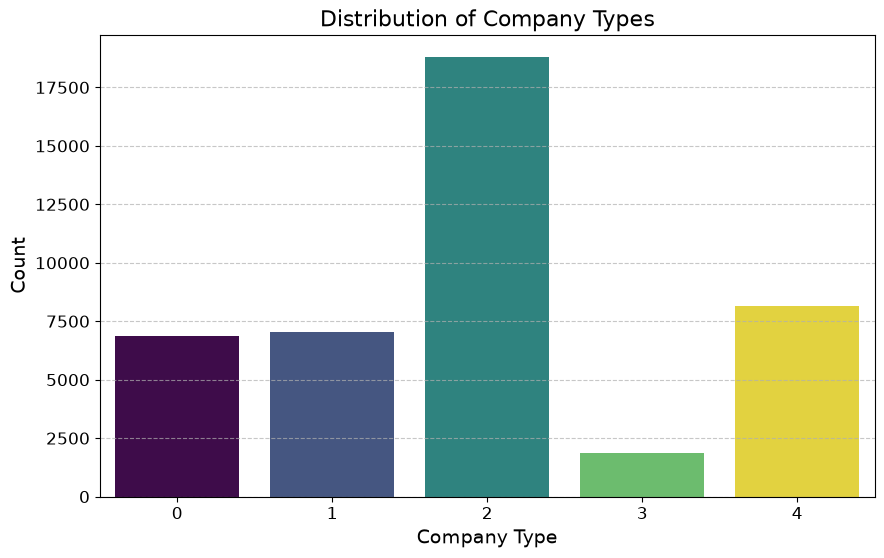

In [94]:
company_type_counts = df_temp['COMPANY_TYPE'].value_counts().reset_index()
company_type_counts.columns = ['COMPANY_TYPE', 'Count']

plt.figure(figsize=(10, 6))
sns.barplot(data=company_type_counts, x='COMPANY_TYPE', y='Count', hue='COMPANY_TYPE', palette='viridis', dodge=False)
plt.title('Distribution of Company Types', fontsize=16)
plt.xlabel('Company Type', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend([], [], frameon=False)  # ซ่อน legend
plt.grid(axis='y', linestyle='--', alpha=0.7);

---

Section 02 : Data Separation

In [95]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

In [96]:
# Load dataset
df_main = pd.read_csv("dataset.csv")

# Perform train_test_split
df_final, df_final = train_test_split(df_main, train_size=0.75, random_state=0)

# Save datasets
df_final.to_csv('dataset_cross.csv', index=False)
df_final.to_csv('dataset_final.csv', index=False)

In [97]:
df_final = pd.read_csv("dataset_cross.csv")

num_of_class_1 = df_final['LABEL'].value_counts()[0]
num_of_class_2 = df_final['LABEL'].value_counts()[1]
print("Number of Class 0 = ", num_of_class_1)
print("Number of Class 1 = ", num_of_class_2)
print("Imbalance Ratio = 1 :", num_of_class_1 / num_of_class_2)

Number of Class 0 =  8849
Number of Class 1 =  1843
Imbalance Ratio = 1 : 4.8014107433532285


In [98]:
df_final = pd.read_csv("dataset_final.csv")

num_of_class_1 = df_final['LABEL'].value_counts()[0]
num_of_class_2 = df_final['LABEL'].value_counts()[1]
print("Number of Class 0 = ", num_of_class_1)
print("Number of Class 1 = ", num_of_class_2)
print("Imbalance Ratio = 1 :", num_of_class_1 / num_of_class_2)

Number of Class 0 =  8849
Number of Class 1 =  1843
Imbalance Ratio = 1 : 4.8014107433532285


---

Section 03 : Classifier Modeling 

In [99]:
# Import Library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
#from xgboost import XGBClassifier

from sklearn.model_selection import cross_validate
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

In [100]:
##--- Prepare cross validation data ---##
df_cross = pd.read_csv('dataset_cross.csv')
df_cross = df_cross.drop(['No'], axis=1)

#--- Define data type ---#
df_cross = df_cross.astype({"SEX": "category"})
df_cross = df_cross.astype({"NO_OF_DEPENDENT": np.int64})
df_cross = df_cross.astype({"MARITAL_STATUS": "category"})
df_cross = df_cross.astype({"YRS_IN_PRESENT_JOB": np.int64})
df_cross = df_cross.astype({"AGE": np.int64})
df_cross = df_cross.astype({"EDUCATION": "category"})
df_cross = df_cross.astype({"YEARS_OF_EXPERIENCE": np.int64})
df_cross = df_cross.astype({"TOTAL_MONTHLY_INCOME": np.int64})
df_cross = df_cross.astype({"LOAN_AMOUNT": np.int64})
df_cross = df_cross.astype({"COMPANY_TYPE": "category"})
df_cross = df_cross.astype({"LABEL": np.int64})

#--- Encode one-hot teatures ---#
df_cross = pd.get_dummies(df_cross, dtype=int)

#--- Prepare cross validation data ---#
X_cross = df_cross.drop(['LABEL'], axis=1)
y_cross = df_cross['LABEL']

In [101]:
##--- Prepare final validation data ---##
df_final = pd.read_csv('dataset_final.csv')
df_final = df_final.drop(['No'], axis=1)

#--- Define data type ---#
df_final = df_final.astype({"SEX": "category"})
df_final = df_final.astype({"NO_OF_DEPENDENT": np.int64})
df_final = df_final.astype({"MARITAL_STATUS": "category"})
df_final = df_final.astype({"YRS_IN_PRESENT_JOB": np.int64})
df_final = df_final.astype({"AGE": np.int64})
df_final = df_final.astype({"EDUCATION": "category"})
df_final = df_final.astype({"YEARS_OF_EXPERIENCE": np.int64})
df_final = df_final.astype({"TOTAL_MONTHLY_INCOME": np.int64})
df_final = df_final.astype({"LOAN_AMOUNT": np.int64})
df_final = df_final.astype({"COMPANY_TYPE": "category"})
df_final = df_final.astype({"LABEL": np.int64})

#--- Encode one-hot teatures ---#
df_final = pd.get_dummies(df_final, dtype=int)

#--- Prepare cross validation data ---#
X_final = df_final.drop(['LABEL'], axis=1)
y_final = df_final['LABEL']

1. Decision Trees Modeling (Benchmark) 

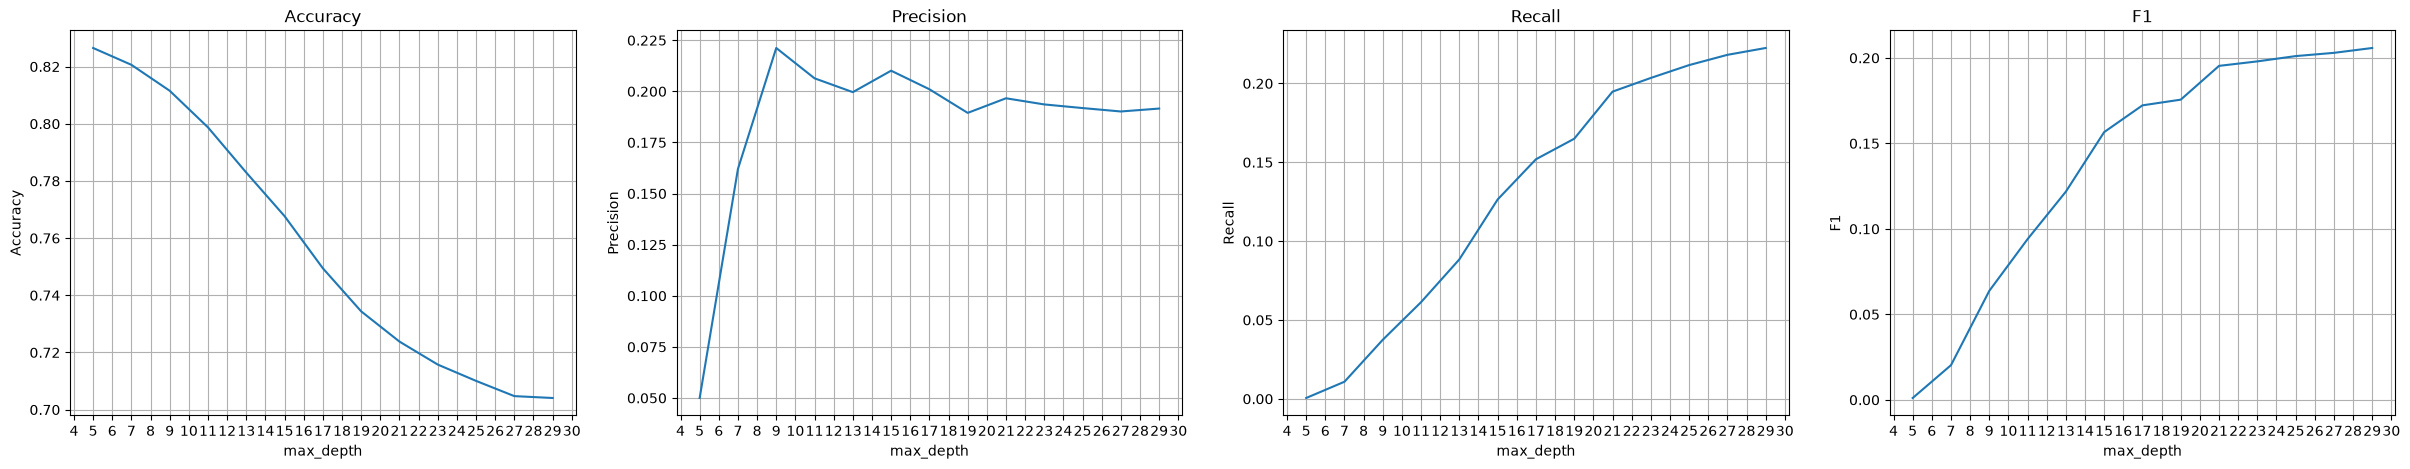

In [102]:
#-- Dependent variables
list_accuracy = []
list_precision = []
list_recall = []
list_f1 = []

#-- Independent variables
list_max_depth = []

#-- Selected algorithms
criterion = 'gini'
spliter = 'best'
#criterion = 'entropy'
#spliter = 'random'

for i in range(5, 30, 2):
    clf = tree.DecisionTreeClassifier(criterion=criterion, splitter=spliter ,max_depth=i)
    scoring = ['accuracy', 'precision', 'recall', 'f1']
    scores = cross_validate(clf, X_cross, y_cross, cv=5, scoring=scoring)
    
    list_accuracy.append(np.mean(scores['test_accuracy']))
    list_precision.append(np.mean(scores['test_precision']))
    list_recall.append(np.mean(scores['test_recall']))
    list_f1.append(np.mean(scores['test_f1'])) 
    list_max_depth.append(i)

metrics = ["Accuracy", "Precision", "Recall", "F1"]
data_lists = [list_accuracy, list_precision, list_recall, list_f1]

fig, axes = plt.subplots(1, 4, figsize=(30, 5))
for ax, metric, data in zip(axes, metrics, data_lists):
    ax.plot(list_max_depth, data)
    ax.grid()
    ax.set_title(metric)
    ax.set_xlabel("max_depth")
    ax.set_ylabel(metric)

    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
    

              precision    recall  f1-score   support

     class 0    0.99955   1.00000   0.99977      8849
     class 1    1.00000   0.99783   0.99891      1843

    accuracy                        0.99963     10692
   macro avg    0.99977   0.99891   0.99934     10692
weighted avg    0.99963   0.99963   0.99963     10692



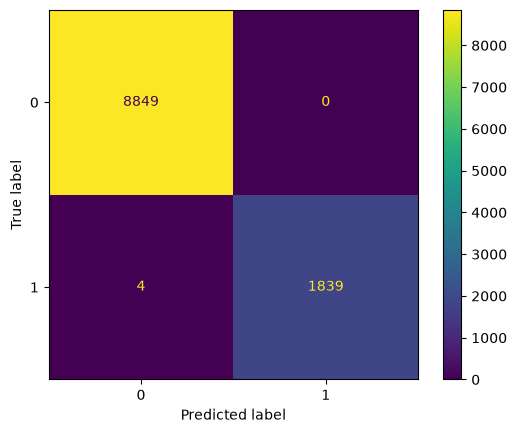

In [103]:
clf = tree.DecisionTreeClassifier(criterion='gini', max_depth=40)
clf.fit(X_cross, y_cross)
y_pred = clf.predict(X_final)

target_names = ['class 0', 'class 1']
print(classification_report(y_final, y_pred, target_names=target_names, digits=5))

cm = confusion_matrix(y_final, y_pred)
cm_display = ConfusionMatrixDisplay(cm).plot()

2. Random Forest Modeling

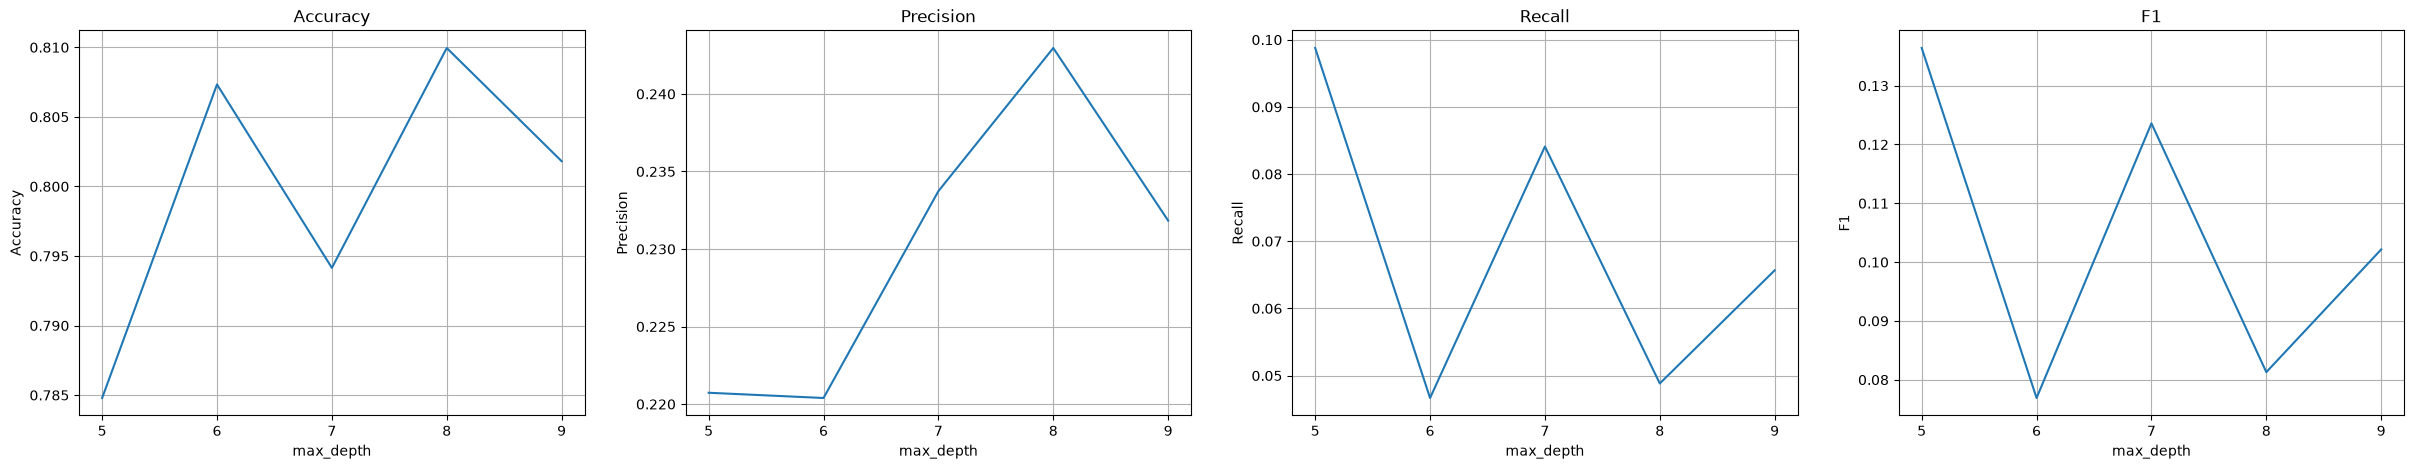

In [104]:
#-- Dependent variables
list_accuracy = []
list_precision = []
list_recall = []
list_f1 = []

#-- Independent variables
list_max_depth = []

#-- Selected algorithms
criterion = 'gini'
#criterion = 'entropy'

for i in range(5, 10):
    clf = RandomForestClassifier(n_estimators=i, criterion=criterion)
    scoring = ['accuracy', 'precision', 'recall', 'f1']
    scores = cross_validate(clf, X_cross, y_cross, cv=5, scoring=scoring)
    
    list_accuracy.append(np.mean(scores['test_accuracy']))
    list_precision.append(np.mean(scores['test_precision']))
    list_recall.append(np.mean(scores['test_recall']))
    list_f1.append(np.mean(scores['test_f1'])) 
    list_max_depth.append(i)

metrics = ["Accuracy", "Precision", "Recall", "F1"]
data_lists = [list_accuracy, list_precision, list_recall, list_f1]

fig, axes = plt.subplots(1, 4, figsize=(30, 5))
for ax, metric, data in zip(axes, metrics, data_lists):
    ax.plot(list_max_depth, data)
    ax.grid()
    ax.set_title(metric)
    ax.set_xlabel("max_depth")
    ax.set_ylabel(metric)

    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
    

              precision    recall  f1-score   support

     class 0    0.98860   0.99989   0.99421      8849
     class 1    0.99943   0.94466   0.97127      1843

    accuracy                        0.99037     10692
   macro avg    0.99401   0.97227   0.98274     10692
weighted avg    0.99047   0.99037   0.99026     10692



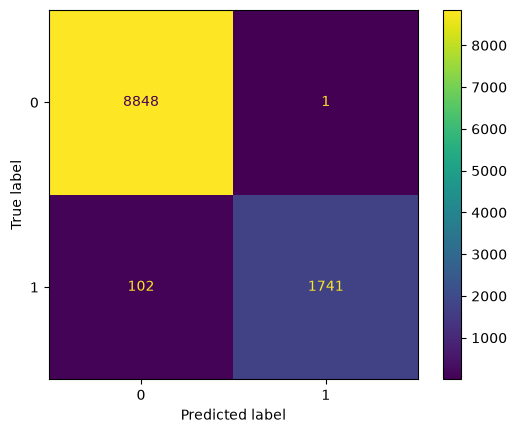

In [105]:
clf = RandomForestClassifier(n_estimators=15, criterion='gini', max_depth=40)
clf.fit(X_cross, y_cross)
y_pred = clf.predict(X_final)

target_names = ['class 0', 'class 1']
print(classification_report(y_final, y_pred, target_names=target_names, digits=5))

cm = confusion_matrix(y_final, y_pred)
cm_display = ConfusionMatrixDisplay(cm).plot()

3. XGBoost Method

In [106]:
##--- XGBoost cross validation process ---#
f1_list = []
accuracy_list = []
precision_list = []
recall_list = []
max_estimators_list = []

for i in range(1, 10):
    clf = XGBClassifier(n_estimators=40, max_depth=i, objective='binary:logistic')
    scoring = ['f1', 'accuracy', 'precision', 'recall']
    scores = cross_validate(clf, X_cross, y_cross, cv=5, scoring=scoring)
    f1_list.append(np.mean(scores['test_f1']))
    accuracy_list.append(np.mean(scores['test_accuracy']))
    precision_list.append(np.mean(scores['test_precision']))
    recall_list.append(np.mean(scores['test_recall']))
    max_estimators_list.append(i)

fig = plt.figure(figsize = (35,5))
plt.subplot(141)
plt.plot(max_estimators_list, f1_list) 
plt.grid() 
plt.title('F1')
plt.xlabel('n_estimator')
plt.ylabel('F1')

plt.subplot(142)
plt.plot(max_estimators_list, accuracy_list) 
plt.grid() 
plt.title('Acuracy')
plt.xlabel('n_estimator')
plt.ylabel('Accuracy')

plt.subplot(143) 
plt.plot(max_estimators_list, precision_list)
plt.grid()
plt.title('Precision')
plt.xlabel('n_estimator')
plt.ylabel('Precision')

plt.subplot(144) 
plt.plot(max_estimators_list, recall_list)
plt.grid()
plt.title('Recall')
plt.xlabel('n_estimator')
plt.ylabel('Recall')

NameError: name 'XGBClassifier' is not defined

In [ ]:
clf = XGBClassifier(n_estimators=40, max_depth=30, objective='binary:logistic')
clf.fit(X_cross, y_cross)
y_pred = clf.predict(X_final)

target_names = ['class 0', 'class 1']
print(classification_report(y_final, y_pred, target_names=target_names, digits=5))

cm = confusion_matrix(y_final, y_pred)
cm_display = ConfusionMatrixDisplay(cm).plot()

---